# EXP004 — Template Alignment for Structured Forms

## Research Question

> **Can a geometrically distorted instance of a fixed-template form be aligned to a reference template accurately enough to support reliable field extraction?**

EXP002 and EXP003 evaluated handwriting recognition on already-segmented IAM text lines. EXP004 moves toward the actual structured-form problem by introducing the document stage that precedes field extraction and HTR.

The initial experiment deliberately isolates **alignment** from handwriting recognition. TrOCR is not used in this notebook yet.


## 1. Experimental Plan

The initial controlled pipeline is:

```text
Reference Template
        ↓
Create controlled geometric distortions
        ↓
Detect local features
        ↓
Match features
        ↓
RANSAC
        ↓
Estimate homography
        ↓
warpPerspective()
        ↓
Aligned document
        ↓
Quantitative + visual alignment analysis
```

The first implementation uses **ORB** as a practical baseline. This is not intended to reproduce the paper's character-keypoint method exactly. Instead, it establishes a reproducible homography-alignment baseline that can later be compared with more document-specific approaches.


In [1]:
from pathlib import Path
import json
import math

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont

np.random.seed(42)

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "forms"
TEMPLATE_DIR = DATA_DIR / "templates"
SAMPLE_DIR = DATA_DIR / "samples"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "exp004"
ALIGNED_DIR = OUTPUT_DIR / "aligned"
FIGURES_DIR = OUTPUT_DIR / "figures"

for d in [TEMPLATE_DIR, SAMPLE_DIR, OUTPUT_DIR, ALIGNED_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Template dir:", TEMPLATE_DIR)
print("Sample dir:", SAMPLE_DIR)
print("Output dir:", OUTPUT_DIR)


Project root: /Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project
Template dir: /Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project/data/forms/templates
Sample dir: /Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project/data/forms/samples
Output dir: /Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project/outputs/exp004


## 2. Create a Controlled Reference Form

To establish the alignment pipeline before introducing real scanned forms, this notebook creates a simple fixed-layout reference form containing printed labels, boxes, lines, and landmarks.

This provides known geometry and makes it possible to generate reproducible distortions with known ground-truth transformations.


Saved reference: /Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project/data/forms/templates/reference_form.png
Field boxes: {'NAME': (400, 215, 1050, 295), 'DATE OF BIRTH': (400, 385, 1050, 465), 'ID NUMBER': (400, 555, 1050, 635), 'PHONE': (400, 725, 1050, 805), 'ADDRESS': (400, 895, 1050, 975), 'CITY': (400, 1065, 1050, 1145), 'ZIP CODE': (400, 1235, 1050, 1315)}


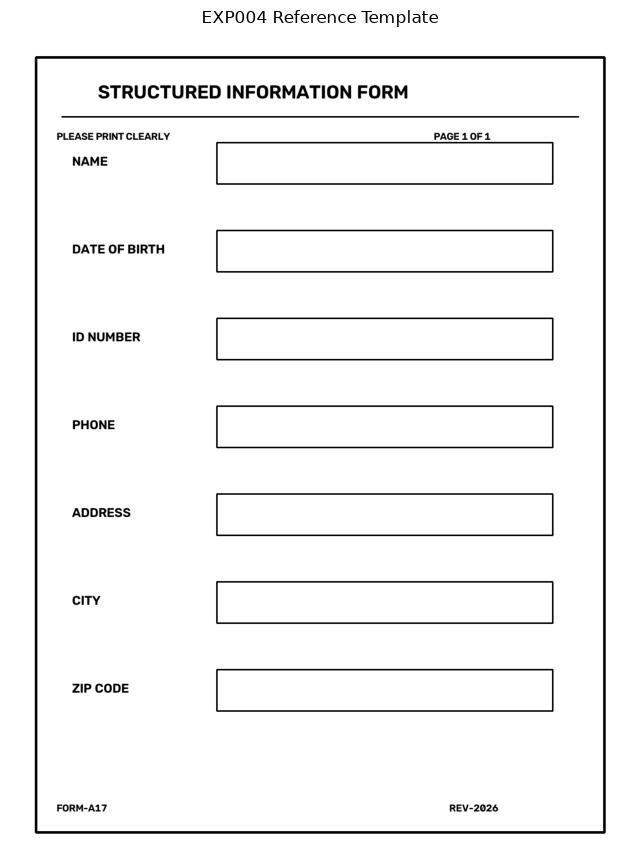

In [2]:
def create_reference_form(width=1200, height=1600):
    img = np.full((height, width, 3), 255, dtype=np.uint8)

    # Outer border and title
    cv2.rectangle(img, (50, 50), (width-50, height-50), (0, 0, 0), 3)
    cv2.putText(img, "STRUCTURED INFORMATION FORM", (170, 130),
                cv2.FONT_HERSHEY_SIMPLEX, 1.25, (0, 0, 0), 3, cv2.LINE_AA)
    cv2.line(img, (100, 165), (width-100, 165), (0, 0, 0), 2)

    fields = [
        ("NAME", 260),
        ("DATE OF BIRTH", 430),
        ("ID NUMBER", 600),
        ("PHONE", 770),
        ("ADDRESS", 940),
        ("CITY", 1110),
        ("ZIP CODE", 1280),
    ]

    field_boxes = {}
    for label, y in fields:
        cv2.putText(img, label, (120, y), cv2.FONT_HERSHEY_SIMPLEX,
                    0.85, (0, 0, 0), 2, cv2.LINE_AA)
        x1, y1, x2, y2 = 400, y-45, 1050, y+35
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 0, 0), 2)
        field_boxes[label] = (x1, y1, x2, y2)

    # Distinctive printed landmarks for feature matching
    for x, y, txt in [(90, 1510, "FORM-A17"), (850, 1510, "REV-2026"),
                      (90, 210, "PLEASE PRINT CLEARLY"), (820, 210, "PAGE 1 OF 1")]:
        cv2.putText(img, txt, (x, y), cv2.FONT_HERSHEY_SIMPLEX,
                    0.65, (0, 0, 0), 2, cv2.LINE_AA)

    return img, field_boxes

reference_img, FIELD_BOXES = create_reference_form()
REFERENCE_PATH = TEMPLATE_DIR / "reference_form.png"
cv2.imwrite(str(REFERENCE_PATH), reference_img)

print("Saved reference:", REFERENCE_PATH)
print("Field boxes:", FIELD_BOXES)

plt.figure(figsize=(8, 11))
plt.imshow(cv2.cvtColor(reference_img, cv2.COLOR_BGR2RGB))
plt.title("EXP004 Reference Template")
plt.axis("off")
plt.show()


## 3. Define Controlled Geometric Distortions

We will test alignment under:

- rotation,
- translation,
- scaling,
- perspective distortion,
- and a combined distortion.

Because these transformations are generated programmatically, the experiment is reproducible.


In [3]:
def rotate_image(img, angle):
    h, w = img.shape[:2]
    center = (w / 2, h / 2)
    M = cv2.getRotationMatrix2D(center, angle, 1.0)
    return cv2.warpAffine(img, M, (w, h), borderValue=(255,255,255))

def translate_image(img, tx, ty):
    h, w = img.shape[:2]
    M = np.float32([[1, 0, tx], [0, 1, ty]])
    return cv2.warpAffine(img, M, (w, h), borderValue=(255,255,255))

def scale_image_center(img, scale):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w/2, h/2), 0, scale)
    return cv2.warpAffine(img, M, (w, h), borderValue=(255,255,255))

def perspective_image(img, offsets):
    h, w = img.shape[:2]
    src = np.float32([[0,0], [w-1,0], [w-1,h-1], [0,h-1]])
    dst = src + np.float32(offsets)
    H = cv2.getPerspectiveTransform(src, dst)
    warped = cv2.warpPerspective(img, H, (w,h), borderValue=(255,255,255))
    return warped

def combined_distortion(img):
    out = rotate_image(img, 5.0)
    out = scale_image_center(out, 0.92)
    out = translate_image(out, 45, -30)
    out = perspective_image(out, [[25,20], [-35,15], [-20,-25], [30,-10]])
    return out

DISTORTIONS = {
    "rotation_5deg": lambda x: rotate_image(x, 5.0),
    "translation": lambda x: translate_image(x, 70, -45),
    "scale_0.90": lambda x: scale_image_center(x, 0.90),
    "perspective": lambda x: perspective_image(x, [[35,25], [-45,20], [-25,-35], [40,-15]]),
    "combined": combined_distortion,
}

distorted_images = {}
for name, fn in DISTORTIONS.items():
    out = fn(reference_img)
    distorted_images[name] = out
    cv2.imwrite(str(SAMPLE_DIR / f"{name}.png"), out)

print("Generated", len(distorted_images), "controlled samples.")


Generated 5 controlled samples.


## 4. Visualize the Distorted Forms

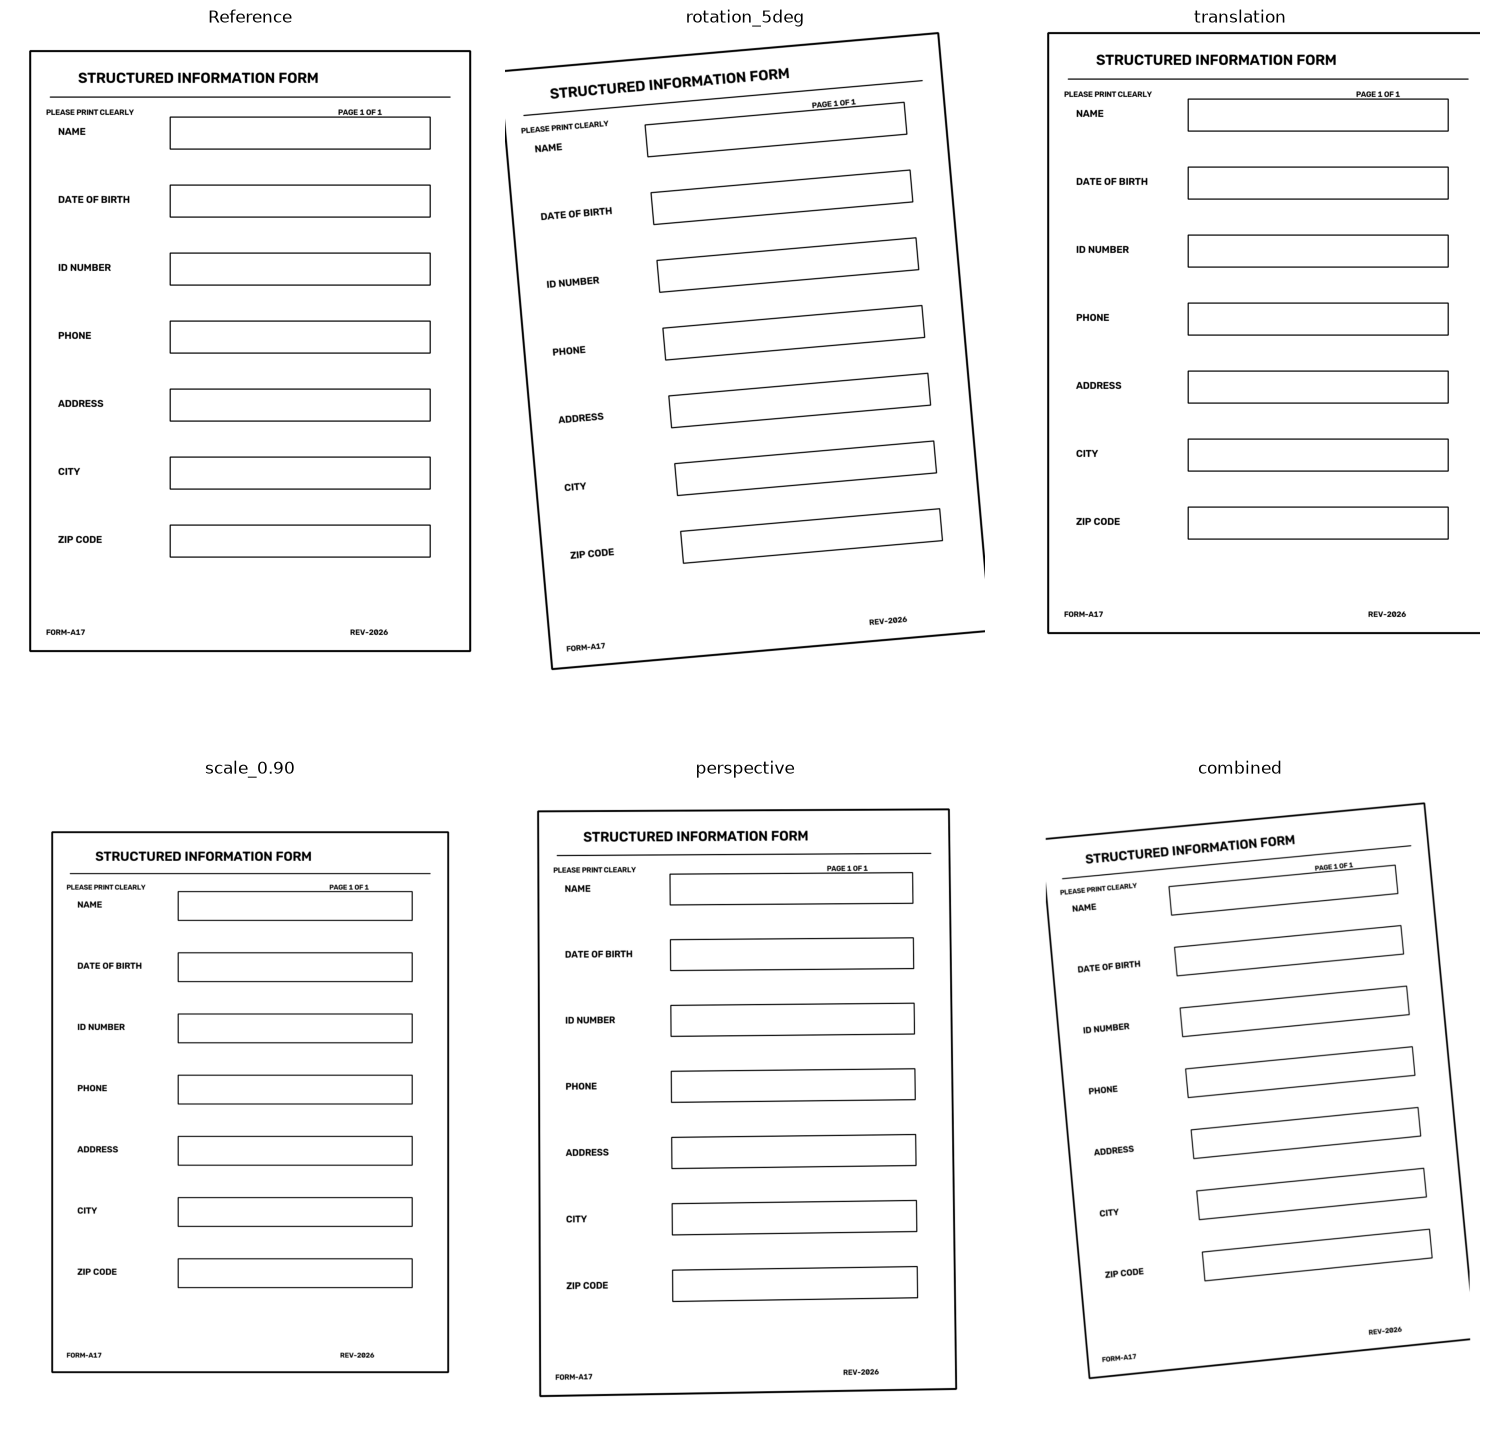

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 16))
axes = axes.ravel()

axes[0].imshow(cv2.cvtColor(reference_img, cv2.COLOR_BGR2RGB))
axes[0].set_title("Reference")
axes[0].axis("off")

for ax, (name, img) in zip(axes[1:], distorted_images.items()):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()


# Stage 2 — ORB + RANSAC Homography Baseline

The paper you reviewed motivates document-specific character keypoints, but EXP004 first establishes a conventional feature-based baseline.

ORB is useful here because it is lightweight and available directly in OpenCV. RANSAC is used during homography estimation to reduce the influence of incorrect matches.


## 5. Implement ORB Feature Matching

In [ ]:
def detect_and_match_orb(reference, moving, nfeatures=5000, keep_fraction=0.30):
    ref_gray = cv2.cvtColor(reference, cv2.COLOR_BGR2GRAY)
    mov_gray = cv2.cvtColor(moving, cv2.COLOR_BGR2GRAY)

    orb = cv2.ORB_create(nfeatures=nfeatures)
    kp_ref, des_ref = orb.detectAndCompute(ref_gray, None)
    kp_mov, des_mov = orb.detectAndCompute(mov_gray, None)

    if des_ref is None or des_mov is None:
        return kp_ref, kp_mov, []

    matcher = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
    matches = matcher.match(des_ref, des_mov)
    matches = sorted(matches, key=lambda m: m.distance)

    keep_n = max(4, int(len(matches) * keep_fraction))
    good_matches = matches[:keep_n]
    return kp_ref, kp_mov, good_matches


## 6. Estimate Homography and Align to the Reference

In [ ]:
def align_to_reference(reference, moving, ransac_threshold=5.0):
    kp_ref, kp_mov, matches = detect_and_match_orb(reference, moving)

    result = {
        "reference_keypoints": len(kp_ref),
        "moving_keypoints": len(kp_mov),
        "matches": len(matches),
        "homography": None,
        "inliers": 0,
        "inlier_ratio": 0.0,
        "success": False,
        "aligned": None,
    }

    if len(matches) < 4:
        return result

    # Query points belong to reference descriptors; train points to moving descriptors.
    ref_pts = np.float32([kp_ref[m.queryIdx].pt for m in matches]).reshape(-1,1,2)
    mov_pts = np.float32([kp_mov[m.trainIdx].pt for m in matches]).reshape(-1,1,2)

    # Map moving image -> reference coordinate system.
    H, mask = cv2.findHomography(mov_pts, ref_pts, cv2.RANSAC, ransac_threshold)
    if H is None or mask is None:
        return result

    inliers = int(mask.ravel().sum())
    h, w = reference.shape[:2]
    aligned = cv2.warpPerspective(moving, H, (w, h), borderValue=(255,255,255))

    result.update({
        "homography": H,
        "inliers": inliers,
        "inlier_ratio": inliers / len(matches),
        "success": True,
        "aligned": aligned,
    })
    return result


## 7. Run Alignment on All Controlled Distortions

In [ ]:
alignment_results = {}
rows = []

for name, moving in distorted_images.items():
    result = align_to_reference(reference_img, moving)
    alignment_results[name] = result

    if result["success"]:
        cv2.imwrite(str(ALIGNED_DIR / f"{name}_aligned.png"), result["aligned"])

    rows.append({
        "sample": name,
        "reference_keypoints": result["reference_keypoints"],
        "moving_keypoints": result["moving_keypoints"],
        "matches": result["matches"],
        "inliers": result["inliers"],
        "inlier_ratio": result["inlier_ratio"],
        "alignment_success": result["success"],
    })

alignment_df = pd.DataFrame(rows)
display(alignment_df)


## 8. Visual Before/After Alignment

A successful homography should map the distorted document back into the reference coordinate system.


In [ ]:
for name, moving in distorted_images.items():
    result = alignment_results[name]
    if not result["success"]:
        print(name, "— alignment failed")
        continue

    fig, axes = plt.subplots(1, 3, figsize=(16, 7))
    axes[0].imshow(cv2.cvtColor(reference_img, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Reference")
    axes[1].imshow(cv2.cvtColor(moving, cv2.COLOR_BGR2RGB))
    axes[1].set_title(f"Distorted — {name}")
    axes[2].imshow(cv2.cvtColor(result["aligned"], cv2.COLOR_BGR2RGB))
    axes[2].set_title("Aligned")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


# Stage 3 — Quantitative Alignment Diagnostics

Visual inspection is useful but insufficient. We also calculate image-space diagnostics against the known reference template.

These metrics are **alignment diagnostics**, not HTR metrics. Lower MAE/RMSE and higher overlap indicate closer geometric agreement.


## 9. Compute Reference-vs-Aligned Image Error

In [ ]:
def alignment_metrics(reference, aligned):
    ref = cv2.cvtColor(reference, cv2.COLOR_BGR2GRAY).astype(np.float32)
    ali = cv2.cvtColor(aligned, cv2.COLOR_BGR2GRAY).astype(np.float32)

    diff = ref - ali
    mae = float(np.mean(np.abs(diff)))
    rmse = float(np.sqrt(np.mean(diff ** 2)))

    # Foreground overlap after a simple threshold.
    _, ref_fg = cv2.threshold(ref.astype(np.uint8), 200, 255, cv2.THRESH_BINARY_INV)
    _, ali_fg = cv2.threshold(ali.astype(np.uint8), 200, 255, cv2.THRESH_BINARY_INV)
    ref_mask = ref_fg > 0
    ali_mask = ali_fg > 0
    intersection = np.logical_and(ref_mask, ali_mask).sum()
    union = np.logical_or(ref_mask, ali_mask).sum()
    iou = float(intersection / union) if union else 1.0

    return {"mae": mae, "rmse": rmse, "foreground_iou": iou}

metric_rows = []
for name, result in alignment_results.items():
    row = {"sample": name}
    if result["success"]:
        row.update(alignment_metrics(reference_img, result["aligned"]))
    else:
        row.update({"mae": np.nan, "rmse": np.nan, "foreground_iou": np.nan})
    metric_rows.append(row)

metrics_df = pd.DataFrame(metric_rows)
full_results_df = alignment_df.merge(metrics_df, on="sample")
display(full_results_df)


## 10. Save EXP004 Baseline Metrics

In [ ]:
METRICS_PATH = OUTPUT_DIR / "orb_alignment_metrics.csv"
full_results_df.to_csv(METRICS_PATH, index=False)
print("Saved:", METRICS_PATH)


## 11. Visualize Match Quality

In [ ]:
plot_df = full_results_df.copy()

plt.figure(figsize=(9,5))
plt.bar(plot_df["sample"], plot_df["inlier_ratio"])
plt.ylabel("RANSAC Inlier Ratio")
plt.xlabel("Controlled Distortion")
plt.title("EXP004 — ORB Homography Inlier Ratio")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,5))
plt.bar(plot_df["sample"], plot_df["foreground_iou"])
plt.ylabel("Foreground IoU")
plt.xlabel("Controlled Distortion")
plt.title("EXP004 — Reference vs Aligned Foreground Overlap")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


# Stage 4 — Demonstrate Why Alignment Matters for Field Extraction

The key thesis motivation is not merely producing visually aligned pages. Alignment should make **fixed template coordinates reusable** for incoming forms.

We demonstrate this using the predefined field boxes from the reference form.


## 12. Crop the Same Template Field Before and After Alignment

In [ ]:
def crop_box(img, box):
    x1, y1, x2, y2 = box
    return img[y1:y2, x1:x2]

DEMO_FIELD = "DATE OF BIRTH"
box = FIELD_BOXES[DEMO_FIELD]

for name in ["rotation_5deg", "perspective", "combined"]:
    moving = distorted_images[name]
    result = alignment_results[name]
    if not result["success"]:
        continue

    unaligned_crop = crop_box(moving, box)
    aligned_crop = crop_box(result["aligned"], box)
    reference_crop = crop_box(reference_img, box)

    fig, axes = plt.subplots(1, 3, figsize=(14,3))
    for ax, im, title in zip(
        axes,
        [reference_crop, unaligned_crop, aligned_crop],
        ["Reference Field", "Same Coordinates Before Alignment", "Same Coordinates After Alignment"]
    ):
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis("off")
    plt.suptitle(f"{DEMO_FIELD} — {name}")
    plt.tight_layout()
    plt.show()


## 13. Initial EXP004 Findings

Complete this section after running the notebook.

Questions to answer:

1. Did ORB + RANSAC successfully estimate a homography for every controlled distortion?
2. Which distortion produced the lowest RANSAC inlier ratio?
3. Which distortion produced the weakest foreground overlap after alignment?
4. Did alignment visibly restore the form to the reference coordinate system?
5. Did fixed template coordinates crop the intended field more reliably after alignment?
6. Where does generic ORB feature matching appear fragile on text-heavy forms?
7. What should be compared next: ORB vs SIFT, or ORB vs a document-specific/character-keypoint method?


# EXP004 Next Steps

After this controlled baseline:

```text
Controlled synthetic form alignment
        ↓
Inspect failure cases
        ↓
Add real scanned / photographed form examples
        ↓
Compare alignment methods if needed
        ↓
Define template field coordinates
        ↓
EXP005 — Structured Field Extraction
        ↓
TrOCR on extracted handwritten fields
```

Do not move directly to HTR until the alignment stage is reliable enough that field crops are geometrically consistent.
